# Image Compression using the Fast Fourier Transform (FFT)

## Motivation

A natural image contains a vast amount of pixel data, but most of that information is concentrated in a small number of low-frequency components. The Fourier Transform lets us exploit this by representing the image in the **frequency domain**, where we can discard unimportant coefficients and reconstruct a visually acceptable image from far fewer numbers.

---

## Algorithm

### 1. Convert to Grayscale
Colour images have 3 channels (R, G, B). For simplicity we work with a single-channel grayscale image $I$, where each pixel value is in $[0, 255]$.

### 2. Compute the 2D Discrete Fourier Transform (DFT)

Apply the 2D FFT to obtain the frequency-domain representation:
$$\hat{I}(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} I(x,y)\, e^{-2\pi i \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$

Each coefficient $\hat{I}(u, v)$ is a complex number capturing the amplitude and phase of a particular spatial frequency $(u, v)$.

### 3. Threshold: Keep Only the Largest Coefficients

Sort all $M \times N$ coefficients by their magnitude $|\hat{I}(u,v)|$.  
Keep only the top $k\%$ and set the rest to zero:
$$\hat{I}_{\text{compressed}}(u,v) = \begin{cases} \hat{I}(u,v) & \text{if } |\hat{I}(u,v)| \geq \tau_k \\ 0 & \text{otherwise} \end{cases}$$

where $\tau_k$ is the magnitude of the $k$-th largest coefficient. This is the compression step — the fewer coefficients retained, the higher the compression ratio.

### 4. Reconstruct via Inverse FFT

Apply the 2D Inverse FFT to recover the image in the spatial domain:
$$I_{\text{rec}}(x, y) = \frac{1}{MN} \sum_{u=0}^{M-1} \sum_{v=0}^{N-1} \hat{I}_{\text{compressed}}(u,v)\, e^{2\pi i \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$

Only the real part is kept (any imaginary residual is numerical noise).

### 5. Measure Reconstruction Error

The quality of the reconstruction is measured using **Mean Squared Error (MSE)**:
$$\text{MSE} = \frac{1}{MN} \sum_{x,y} \left(I(x,y) - I_{\text{rec}}(x,y)\right)^2$$

A lower MSE means the reconstructed image is closer to the original. As the compression ratio increases (fewer coefficients kept), the MSE rises.

---

## Key Insight

Image energy is **concentrated in low frequencies** (large-magnitude coefficients near the centre of the spectrum). Discarding the small high-frequency coefficients causes only minor visual degradation, enabling high compression ratios with acceptable quality — the principle behind JPEG compression.

Image size: (1500, 2000) (width x height)
Image mode: RGB
Array shape: (2000, 1500, 3)


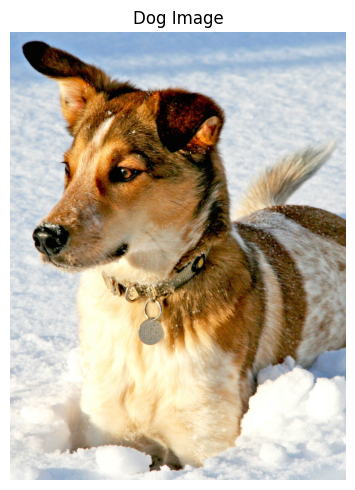

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Load the dog image
img = Image.open(os.path.join('..', 'DATA', 'dog.jpg'))
img_array = np.array(img)

print(f"Image size: {img.size} (width x height)")
print(f"Image mode: {img.mode}")
print(f"Array shape: {img_array.shape}")

plt.figure(figsize=(6, 5))
plt.imshow(img_array)
plt.title('Dog Image')
plt.axis('off')
plt.tight_layout()
plt.show()


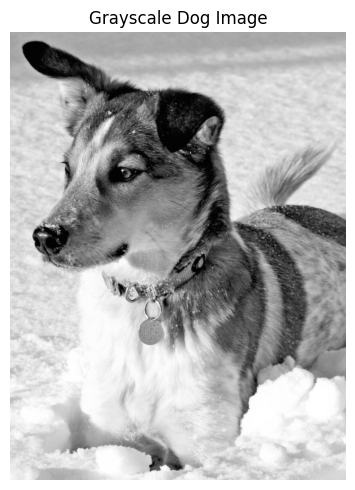

Grayscale image shape: (2000, 1500)


In [ ]:
# Convert to grayscale, 'L' is for luminance (grayscale)
img_gray = np.array(img.convert('L'), dtype=np.float64)

plt.figure(figsize=(6, 5))
plt.imshow(img_gray, cmap='gray')
plt.title('Grayscale Dog Image')
plt.axis('off')
plt.tight_layout()
plt.show()

print(f"Grayscale image shape: {img_gray.shape}")


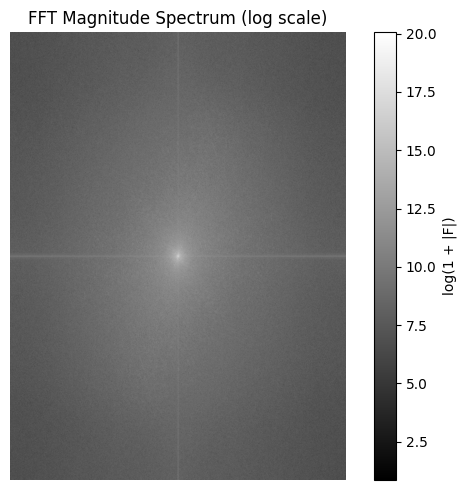

In [8]:
from scipy.fft import fft2, ifft2, fftshift, ifftshift

# Compute 2D FFT of the grayscale image
F = fft2(img_gray)
F_shifted = fftshift(F)   # shift zero frequency to centre

# FFT magnitude spectrum (log scale for visualisation)
magnitude = np.log1p(np.abs(F_shifted))

plt.figure(figsize=(6, 5))
plt.imshow(magnitude, cmap='gray')
plt.title('FFT Magnitude Spectrum (log scale)')
plt.axis('off')
plt.colorbar(label='log(1 + |F|)')
plt.tight_layout()
plt.show()


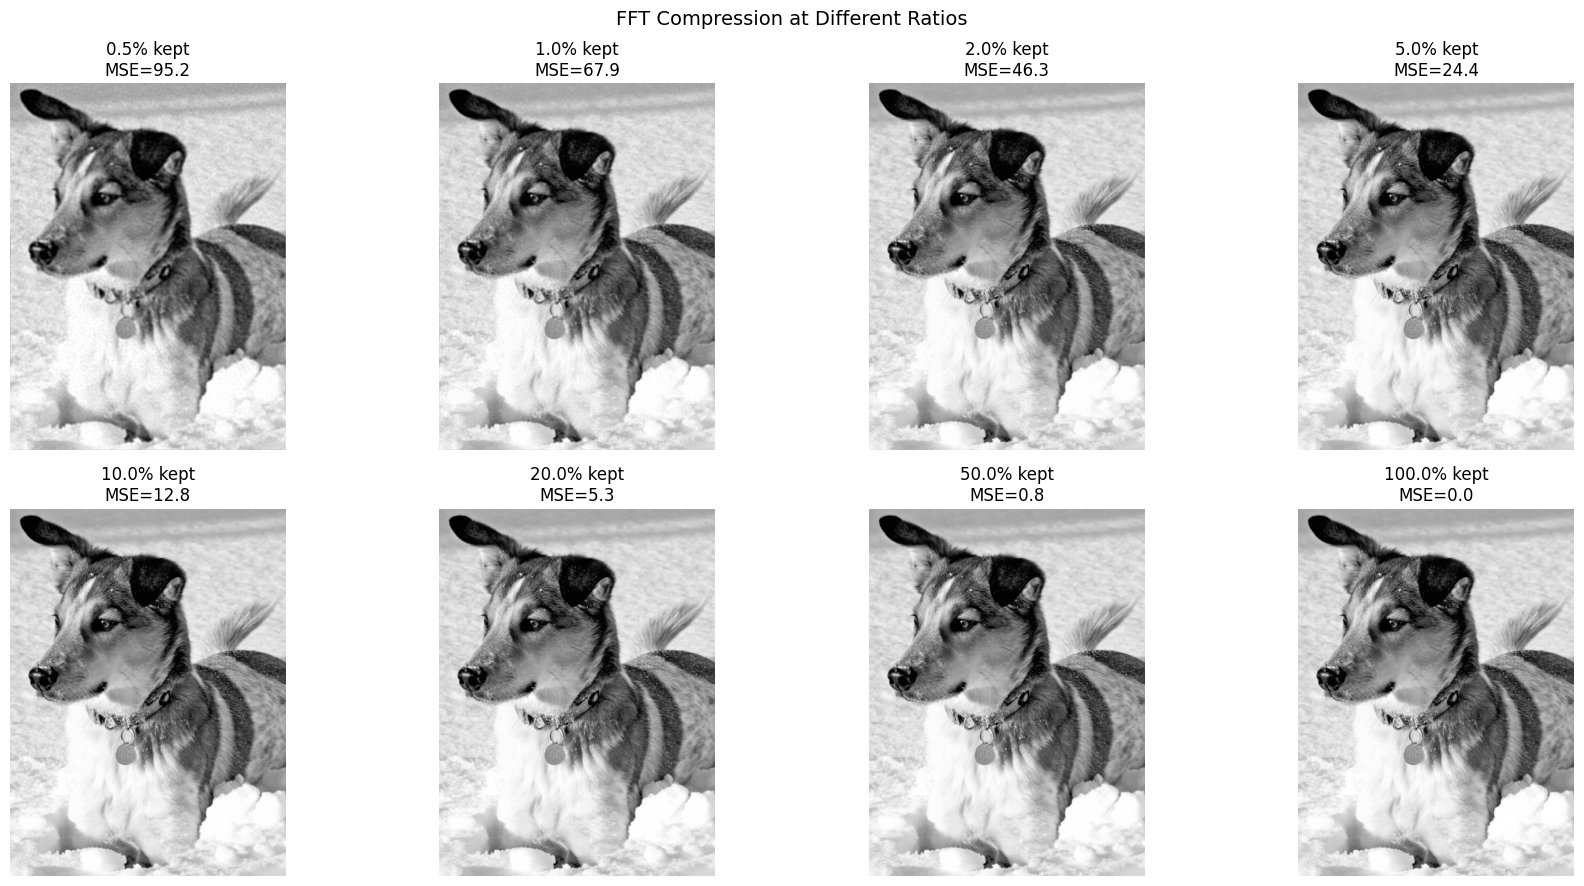

In [9]:
# FFT Compression: keep only the top k% of coefficients by magnitude
# Sort all coefficients by magnitude, zero out the smallest ones

def compress_fft(img_gray, keep_fraction):
    """Compress image by keeping only top `keep_fraction` of FFT coefficients."""
    F = fft2(img_gray)
    F_flat = F.flatten()
    # Find threshold: keep the top `keep_fraction` by magnitude
    magnitudes = np.abs(F_flat)
    threshold = np.sort(magnitudes)[::-1][int(keep_fraction * len(magnitudes)) - 1]
    F_compressed = F.copy()
    F_compressed[np.abs(F_compressed) < threshold] = 0
    img_reconstructed = np.real(ifft2(F_compressed))
    n_kept = np.count_nonzero(F_compressed)
    return img_reconstructed, n_kept

# Test a range of compression ratios (fraction of coefficients kept)
keep_fractions = [0.005, 0.01, 0.02, 0.05, 0.10, 0.20, 0.50, 1.0]
errors = []
kept_counts = []

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for idx, kf in enumerate(keep_fractions):
    img_rec, n_kept = compress_fft(img_gray, kf)
    mse = np.mean((img_gray - img_rec) ** 2)
    errors.append(mse)
    kept_counts.append(n_kept)

    axes[idx].imshow(img_rec, cmap='gray', vmin=0, vmax=255)
    axes[idx].set_title(f'{kf*100:.1f}% kept\nMSE={mse:.1f}')
    axes[idx].axis('off')

plt.suptitle('FFT Compression at Different Ratios', fontsize=14)
plt.tight_layout()
plt.show()


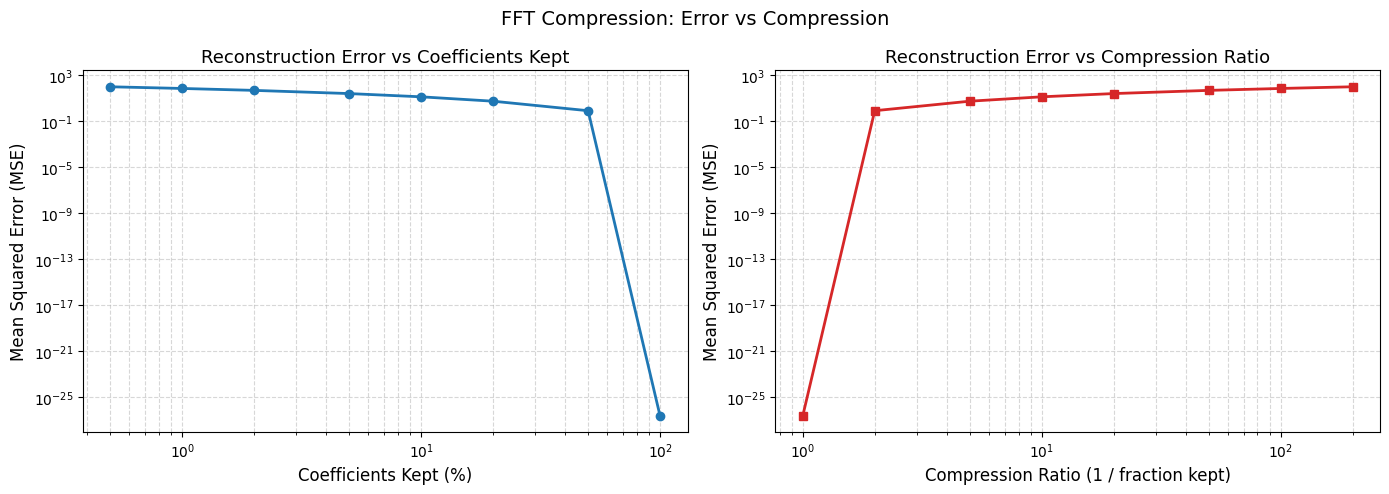

    Kept %    Compression          MSE    Coefficients
-------------------------------------------------------
       0.5          200.0        95.19           15001
       1.0          100.0        67.91           30001
       2.0           50.0        46.27           60001
       5.0           20.0        24.40          150001
      10.0           10.0        12.75          300001
      20.0            5.0         5.30          600000
      50.0            2.0         0.79         1500001
     100.0            1.0         0.00         3000000


In [10]:
# Plot reconstruction error vs compression ratio
compression_ratios = [1.0 / kf for kf in keep_fractions]   # ratio = 1 / fraction kept

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# MSE vs % of coefficients kept
axes[0].plot([kf * 100 for kf in keep_fractions], errors, 'o-', color='tab:blue', lw=2)
axes[0].set_xlabel('Coefficients Kept (%)', fontsize=12)
axes[0].set_ylabel('Mean Squared Error (MSE)', fontsize=12)
axes[0].set_title('Reconstruction Error vs Coefficients Kept', fontsize=13)
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].grid(True, which='both', ls='--', alpha=0.5)

# MSE vs compression ratio
axes[1].plot(compression_ratios, errors, 's-', color='tab:red', lw=2)
axes[1].set_xlabel('Compression Ratio (1 / fraction kept)', fontsize=12)
axes[1].set_ylabel('Mean Squared Error (MSE)', fontsize=12)
axes[1].set_title('Reconstruction Error vs Compression Ratio', fontsize=13)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].grid(True, which='both', ls='--', alpha=0.5)

plt.suptitle('FFT Compression: Error vs Compression', fontsize=14)
plt.tight_layout()
plt.show()

# Summary table
print(f"{'Kept %':>10s} {'Compression':>14s} {'MSE':>12s} {'Coefficients':>15s}")
print("-" * 55)
for kf, cr, mse, n in zip(keep_fractions, compression_ratios, errors, kept_counts):
    print(f"{kf*100:>10.1f} {cr:>14.1f} {mse:>12.2f} {n:>15d}")
